# 04 · Splitting, normalising and baselines (pipeline steps 5 and 6)

**Splitting.** The data is split by recording, never by window, because neighbouring windows overlap heavily.
With only 8 recordings a single hold-out split would test on one file, so we use 5-fold cross-validation:
every recording is a test recording exactly once, and the model that tests it has never seen it.

**Normalising.** Features and targets are scaled to mean 0 and standard deviation 1, using the training recordings only.

**Baselines.** Two simple guesses that need no training. A trained model is only useful if it beats them.
- *Stay still:* predict that nothing moves.
- *Constant velocity:* predict that every point keeps moving with its recent average velocity.

**Input:** `data/interim/`. **Output:** `reports/baselines.csv` and `reports/figures/baselines.png`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from strikefit_ml.datasets import build_windows, check_split, compute_norm, make_splits, pooled_test_files, split_summary, stack
from strikefit_ml.evaluation import compare_tables, displacement_errors_cm, error_table, overall, predict_constant_velocity, predict_still
from strikefit_ml.feature_engineering import FEATURE_NAMES
from strikefit_ml.ingestion import load_config, resolve
from strikefit_ml.preprocessing import load_segments

pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
cfg = load_config()
figures = resolve(cfg, "figures_dir")
figures.mkdir(parents=True, exist_ok=True)
segments = load_segments(resolve(cfg, "interim_dir"))
windows = build_windows(segments, cfg)
horizons, rate = cfg["horizons_frames"], cfg["sample_rate_hz"]

## Step 5: split by recording

In [2]:
files = sorted(windows)
splits = make_splits(files, cfg)
for s in splits:
    check_split(s)
method = "cross-validation by recording" if len(splits) > 1 else "a single hold-out split"
print(f"{len(files)} recordings (a hold-out split needs at least {cfg['split']['min_files_for_holdout']}) -> {method}, {len(splits)} fold(s)")
summary = pd.concat([split_summary(s, windows, segments, cfg) for s in splits])
summary

8 recordings (a hold-out split needs at least 10) -> cross-validation by recording, 5 fold(s)


,split,part,files,segments,windows,minutes
0,fold0,train,5,5,4874,8.280
1,fold0,val,1,1,769,1.310
2,fold0,test,2,2,1460,2.500
0,fold1,train,5,5,4153,7.080
1,fold1,val,1,1,833,1.420
2,fold1,test,2,2,2117,3.590
0,fold2,train,5,5,4145,7.070
1,fold2,val,1,1,1010,1.720
2,fold2,test,2,2,1948,3.310
0,fold3,train,6,6,5251,8.940


In [3]:
print("average per fold:")
display(summary.groupby("part")[["files", "segments", "windows", "minutes"]].mean().round(2))
print({s.name: {"train": len(s.train), "val": len(s.val), "test": len(s.test)} for s in splits})
print("no recording is in two parts of a fold, and each recording is a test recording exactly once:", sorted(pooled_test_files(splits)) == sorted(files))

average per fold:


,files,segments,windows,minutes
part,,,,
test,1.600,1.600,"1,420.600",2.420
train,5.400,5.400,"4,784.800",8.150
val,1.000,1.000,897.600,1.530


{'fold0': {'train': 5, 'val': 1, 'test': 2}, 'fold1': {'train': 5, 'val': 1, 'test': 2}, 'fold2': {'train': 5, 'val': 1, 'test': 2}, 'fold3': {'train': 6, 'val': 1, 'test': 1}, 'fold4': {'train': 6, 'val': 1, 'test': 1}}
no recording is in two parts of a fold, and each recording is a test recording exactly once: True


## Normalisation uses the training recordings only
Shown for fold 0. The test recordings must not influence these numbers, otherwise the test score would be too optimistic.

In [4]:
fold0 = splits[0]
train = stack(windows, list(fold0.train))
norm = compute_norm(train["x"], train["y"])
pd.DataFrame({"mean": norm.x_mean, "std": norm.x_std}, index=FEATURE_NAMES).T.round(3)

,head_rel_x,head_rel_y,head_rel_z,controlling_hand_rel_x,controlling_hand_rel_y,controlling_hand_rel_z,secondary_hand_rel_x,secondary_hand_rel_y,secondary_hand_rel_z,head_vel_x,...,controlling_hand_vel_x,controlling_hand_vel_y,controlling_hand_vel_z,secondary_hand_vel_x,secondary_hand_vel_y,secondary_hand_vel_z,controlling_hand_speed,secondary_hand_speed,head_height_z,grip
mean,-0.002,-0.001,0.000,0.041,0.107,-0.415,-0.120,-0.176,-0.650,0.004,...,0.004,-0.001,0.002,0.004,0.002,0.001,2.378,1.426,1.527,1.000
std,0.091,0.096,0.035,0.284,0.321,0.385,0.265,0.259,0.367,0.235,...,1.748,1.523,1.727,1.169,0.958,1.167,1.643,1.270,0.059,1.000


In [5]:
test = stack(windows, list(fold0.test))
print(f"fold 0 is trained on {len(fold0.train)} recordings. The first 3 targets have a standard deviation (cm) of")
print("  training data:", np.round(norm.y_std[:3] * 100, 1), "  test data:", np.round(test["y"].std(0)[:3] * 100, 1))
print("a column that never changes (grip) gets a standard deviation of 1 instead of 0:", norm.x_std[-1])

fold 0 is trained on 5 recordings. The first 3 targets have a standard deviation (cm) of
  training data: [5.5 5.8 2.6]   test data: [6.1 6.3 3.9]
a column that never changes (grip) gets a standard deviation of 1 instead of 0: 1.0


## Step 6: baselines on the test recordings
Each recording is a test recording once, so all recordings together are scored.

In [6]:
test_files = pooled_test_files(splits)
test = stack(windows, test_files)
still = predict_still(len(test["y"]), len(horizons))
velocity = predict_constant_velocity(test["raw"], rate, horizons, cfg["data"]["velocity_mean_frames"])

table_still = error_table(displacement_errors_cm(still, test["y"]), test["file_idx"], cfg)
table_velocity = error_table(displacement_errors_cm(velocity, test["y"]), test["file_idx"], cfg)
compare_tables({"stay still": table_still, "constant velocity": table_velocity})

,horizon_s,entity,stay still,constant velocity
0,0.250,head,"7.57 [7.04, 8.01]","6.94 [6.53, 7.31]"
1,0.250,controlling hand,"52.08 [50.34, 53.84]","69.78 [66.23, 73.24]"
2,0.250,secondary hand,"33.12 [31.39, 35.01]","40.36 [37.94, 43.06]"
3,0.250,all entities,"30.92 [29.83, 32.07]","39.03 [37.04, 40.90]"
4,0.500,head,"12.97 [11.95, 13.81]","17.21 [16.22, 18.13]"
5,0.500,controlling hand,"79.34 [77.14, 81.49]","149.79 [143.66, 155.90]"
6,0.500,secondary hand,"52.56 [50.05, 55.26]","90.55 [85.44, 96.23]"
7,0.500,all entities,"48.29 [46.71, 49.83]","85.85 [82.36, 89.44]"
8,0.750,head,"16.06 [14.72, 17.23]","27.97 [26.17, 29.71]"
9,0.750,controlling hand,"85.75 [83.91, 87.61]","214.39 [206.82, 222.04]"


In [7]:
reports = resolve(cfg, "reports_dir")
reports.mkdir(parents=True, exist_ok=True)
both = pd.concat([table_still.assign(model="stay still"), table_velocity.assign(model="constant velocity")])
both[["model", "horizon_s", "entity", "mean_cm", "ci_low", "ci_high"]].to_csv(reports / "baselines.csv", index=False)
print(f"saved reports/baselines.csv | {len(test['y'])} test windows from {len(test_files)} recordings")
print(f"overall error: stay still {overall(table_still):.1f} cm, constant velocity {overall(table_velocity):.1f} cm")

saved reports/baselines.csv | 7103 test windows from 8 recordings
overall error: stay still 46.8 cm, constant velocity 101.6 cm


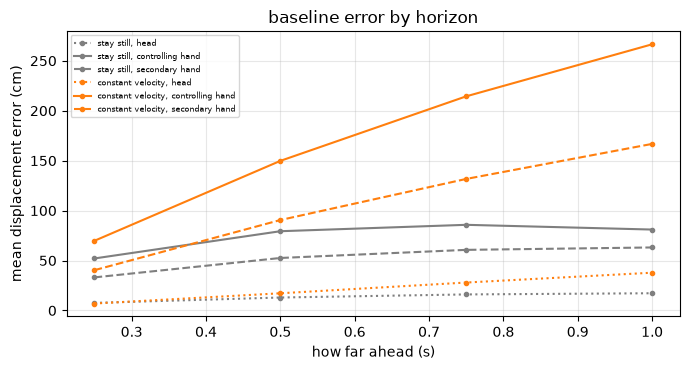

In [8]:
fig, ax = plt.subplots(figsize=(7, 3.8))
horizons_s = [h / rate for h in horizons]
for name, table, colour in (("stay still", table_still, "tab:gray"), ("constant velocity", table_velocity, "tab:orange")):
    for entity, style in (("head", ":"), ("controlling hand", "-"), ("secondary hand", "--")):
        rows = table[(table.entity == entity) & (table.horizon_s != "all")]
        ax.plot(horizons_s, rows.mean_cm, style, color=colour, marker="o", ms=3, label=f"{name}, {entity}")
ax.set_xlabel("how far ahead (s)")
ax.set_ylabel("mean displacement error (cm)")
ax.set_title("baseline error by horizon")
ax.legend(fontsize=6)
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(figures / "baselines.png", dpi=130)
plt.show()